In [12]:
# Code imports
from lib.opt_types import *
from lib.utils import *

# Image inpainting with proximal methods - 30 points + 2 bonus points

Image in-painting consists of reconstructing the missing parts of an image from a given incomplete image.

By exploiting some prior knowledge on the image, it is possible to in-paint images that have a large portion of their pixels missing. In this part of the homework, we are going to study different methods to achieve this goal.

We consider a subsampled image $\mathbf{b} = \mathbf{P}_{\Omega} \mathbf{x}$, where $\mathbf{P}_{\Omega} \in \mathbb{R}^{n \times p}$ is an operator that selects only few, $n \ll p := m^2$, pixels from the vectorized image $\mathbf{x} \in \mathbb{R}^p$. Our goal is to reconstruct the original image $\mathbf{x}$.

### Prior knowledge

Image inpainting is impossible without having some prior knowledge on the structure of the true image $\mathbf{x}$. 

We will explore and compare the following prior assumptions we can make on the true image: 
>  **Assumption**: There exists a orthonormal basis $\mathbf{W} \in \mathbb{R}^{p\times p}$ such that $\mathbf{x}$ can be sparsely represented in that basis, i.e, $\mathbf{W} \mathbf{x}$ is a vector with few non-zero coefficients. Writing $\boldsymbol\alpha=\mathbf W\mathbf x$, we have $\mathbf x=\mathbf W^\top\boldsymbol\alpha$. We promote sparsity by penalizing $\|\boldsymbol\alpha\|_1$, a convex surrogate for the number of nonzero coefficients. We assume that this basis is known and corresponds to the _wavelet basis_. Under this assumption, the reconstruction problem corresponds to solving the following optimization problem:
$$
\min_{\mathbf{\alpha} \in \mathbb{R}^{p}} \underbrace{ \frac{1}{2}\|\mathbf{b} - \mathbf{P}_{\Omega} \mathbf{W}^T\mathbf{\alpha} \|_2^2}_{f_{\ell_1}(\mathbf{\alpha})} + \underbrace{\lambda_{\ell_1} \|\mathbf{\alpha}\|_1}_{g_{\ell_1}(\mathbf{\alpha})},
$$
where $\lambda_{\ell_1}$ is a coefficient we will need to choose.



# PART 1: Optimizing with an $\ell_1$ norm regularization

The optimization problem we are looking to solve have an objective function of the form:
$$
	 f(\mathbf{x}) + g(\mathbf{x}).
$$

These types of objectives are referred to as _composite objectives_ where one term, $f$, is smooth and differentiable and the other term $g$ is non-differentiable.

---

## Code structure:

Recall that we have been working with the `Function` type so far. We will augment this type to represent functions that are not differentiable:

- Given a `Function` `g` you can obtain a subgradient at a point `x` by calling `g.subgrad(x)`.

Moreover, since we are dealing with _composite_ problems with a an objective function that can be written `f + g`, we define the `CompositeFunction` type defined as
```python
@dataclass
class CompositeFunction:
    f: Function
    g: Function
```

The iterative schemes you will implement will receive a composite function that they can unpack as follows:

```python
def state_update(composite_function, state):
    f, g = composite_function

```

#### Question 1: (5 point)

A first approach to solve a non-smooth optimization problem can be to turn to subgradients. Review slide 42-44 of Lecture 6, and implement `SubG` with $\alpha_k = \frac{0.1}{\sqrt{k}}$, starting the counter at $k=1$.

In [13]:
@dataclass
class SubG_state(OptState):
    x_k: Vector
    k: int

In [14]:
def SubG_update(composite_function, state):
    f, g = composite_function
    x_k, k = state

    alpha_k = 0.1 / np.sqrt(k)
    direction = f.grad(x_k) + g.subgrad(x_k)
    x_next = x_k - alpha_k * direction

    return SubG_state(x_k=x_next, k=k + 1)


def SubG_initialize(composite_function, x_zero):
    return SubG_state(x_k=x_zero, k=1)

In [15]:
SubG = OptAlgorithm(name="SubG", init_state=SubG_initialize, state_update=SubG_update)

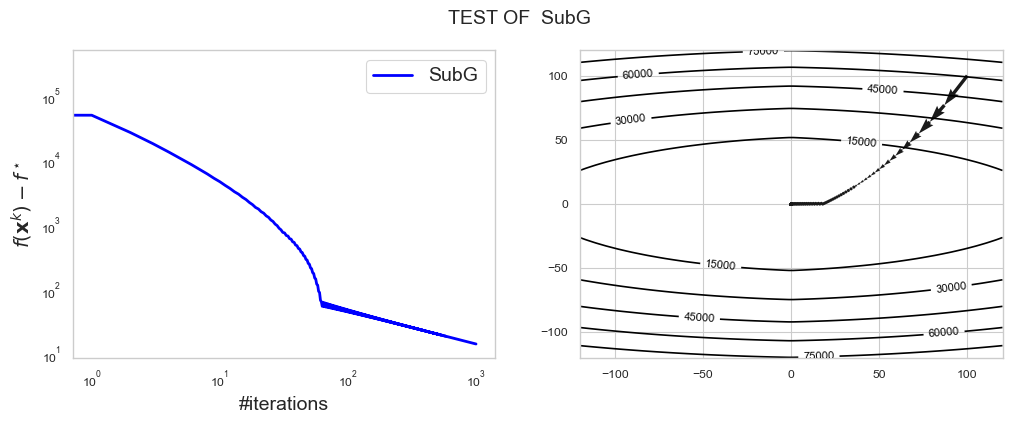

In [16]:
test_composite(SubG)


---

Another, more efficient approach, as we saw in Lecture 8, is to minimize such a function by using proximal gradient algorithms, provided that $g$ is _proximable_ (i.e., its proximal operator is efficient to evaluate). We recall the proximal operator of $g$ as the solution to the following convex problem:
$$
\mathrm{prox}_g(\mathbf{z}) := \mathrm{arg}\min_{\mathbf{y}\in\mathbb{R}^d}\{ g(\mathbf{y}) + \frac{1}{2}\Vert\mathbf{y} - \mathbf{z}\Vert_2^2\}.
$$

#### Question 2 (2 points)

Given $g_{\ell_1}: \mathbb{R}^p \rightarrow \mathbb{R}, \; g_{\ell_1}(\mathbf{x}) :=  \beta \|\mathbf{x}\|_1$ with $\beta\geq0$, show that its proximal function can be written as
    $$
    \mathrm{prox}_{\gamma g_{\ell_1}}(\mathbf{z}) = \max(|\mathbf{z}|-\beta \gamma,0) \circ \mathrm{sign}(\mathbf{z}), \; \text{for any }\mathbf{z} \in \mathbb{R}^p,\; \gamma \in \mathbb{R}_+
    $$
			where the operators $\max$, $\mathrm{sign}$ and $\lvert \cdot \lvert$ are applied coordinate-wise to the vector $\mathbf{z}$ and $\circ$ stands for $(\mathbf{x} \circ \mathbf{y})_i = x_i y_i$. Such a regularizer imposes sparsity on the solutions.



We start from the definition of the proximal operator:


For $\gamma>0$,
$$
\operatorname{prox}_{\gamma g_{\ell_1}}(\mathbf{z})
=
\arg\min_{\mathbf{x}\in\mathbb{R}^p}
\left\{
g_{\ell_1}(\mathbf{x})
+\frac{1}{2\gamma}\|\mathbf{x}-\mathbf{z}\|_2^2
\right\}.
$$


$$
\operatorname{prox}_{\gamma g_{\ell_1}}(\mathbf{z})
=
\arg\min_{\mathbf{x}\in\mathbb{R}^p}
\left\{
\beta\sum_{i=1}^p |x_i|
+\frac{1}{2\gamma}\sum_{i=1}^p (x_i-z_i)^2
\right\}.
$$


So for each coordinate:
$$
x_i^\star
=
\arg\min_{x_i\in\mathbb{R}}
\left\{
\beta|x_i|+\frac{1}{2\gamma}(x_i-z_i)^2
\right\}.
=
\arg\min_{x_i\in\mathbb{R}} h(x_i),
\qquad
h(x_i)=\frac12(x_i-z_i)^2+\beta\gamma|x_i|.
$$


Since $h$ is convex $x_i^\star$ minimizes IFF
$$
0\in\partial h(x_i^\star) \iff 
0\in x_i^\star-z_i+\beta\gamma\,\partial|x_i^\star|,
$$

which gives
$$
z_i-x_i^\star\in\beta\gamma\,\partial|x_i^\star|.
$$

Since

$$
\partial|x_i|=
\begin{cases}
\{1\}, & x_i>0,\\
\{-1\}, & x_i<0,\\
[-1,1], & x_i=0.
\end{cases}
$$

Consider three cases.

1) $x_i^\star>0$

Then $\partial|x_i^\star|=\{1\}$, so:
$$
0=x_i^\star-z_i+\lambda
\quad\Longrightarrow\quad
x_i^\star=z_i-\lambda.
$$
This  is positive  when $z_i>\lambda$. Therefore, $z_i>\beta\gamma$,
$$
x_i^\star=z_i-\beta\gamma>0.
$$

2) $x_i^\star<0$

Then $\partial|x_i^\star|=\{-1\}$, so:
$$
0=x_i^\star-z_i-\lambda
\quad\Longrightarrow\quad
x_i^\star=z_i+\lambda.
$$
This is negative  when $z_i<-\lambda$. Therefore,  $z_i<-\beta\gamma$,
$$
x_i^\star=z_i+\beta\gamma<0.
$$

3) $x_i^\star=0$

$\partial|x_i^\star|=[-1,1]$, so:
$$
0\in -z_i+\lambda[-1,1],
$$
or
$$
z_i\in\lambda[-1,1].
$$
This holds when $|z_i|\le\lambda$. Therefore,  $|z_i|\le\beta\gamma$,
$$
x_i^\star=0.
$$

Hence:
$$
x_i^\star=
\begin{cases}
z_i-\beta\gamma, & z_i>\beta\gamma,\\
0, & |z_i|\le\beta\gamma,\\
z_i+\beta\gamma, & z_i<-\beta\gamma.
\end{cases}
$$

This is:
$$
x_i^\star
=
\operatorname{sign}(z_i)\max\bigl(|z_i|-\beta\gamma,\,0\bigr).
$$

Or in vector form:
$$
\boxed{
\operatorname{prox}_{\gamma g_{\ell_1}}(\mathbf{z})
=
\operatorname{sign}(\mathbf{z})
\circ
\max\bigl(|\mathbf{z}|-\beta\gamma\mathbf{1},\,\mathbf{0}\bigr)
}
$$

Q.E.D.


#### Question 3 (1 point)
 Fill in the function `l1_prox` with the proximal operator of $g_{\ell_1}$.

In [17]:
def l1_prox(gamma, z, beta):
    return np.sign(z) * np.maximum(np.abs(z) - beta * gamma, 0.0)

#### Question 4 (4 points)

From here on, in order to speed-up the convergence of the optimization, let's assume that the function $f$ has been made to be $\mu$-strongly convex by the addition of an $\ell_2$ regularization term to the function $f$, while the $\ell_1$ term, $g$, has remained unchanged. As such, we must now utilize the strong-convexity versions of the composite optimization algorithms.

Using the information in Lecture 7 slide 21 fill in the codes of the method $\text{ISTA}_\mu$. In the provided quadratic test, $\beta=30$. Use `g.prox(alpha, z)` to apply the proximal operator of the supplied regularizer, including its weight.

In [18]:
@dataclass
class ISTA_state(OptState):
    x_k: Vector
    alpha_k: float

In [19]:
def ISTA_update(composite_function, state):
    f, g = composite_function
    x_k, alpha_k = state

    gradient_step = x_k - alpha_k * f.grad(x_k)
    x_next = g.prox(alpha_k, gradient_step)

    return ISTA_state(x_k=x_next, alpha_k=alpha_k)


def ISTA_initialize(composite_function, x_zero):
    f, g = composite_function
    alpha_k = 2.0 / (f.lips_grad + f.strng_cvx)
    return ISTA_state(x_k=x_zero, alpha_k=alpha_k)

In [20]:
ISTA = OptAlgorithm(name="ISTA", init_state= ISTA_initialize, state_update=ISTA_update)

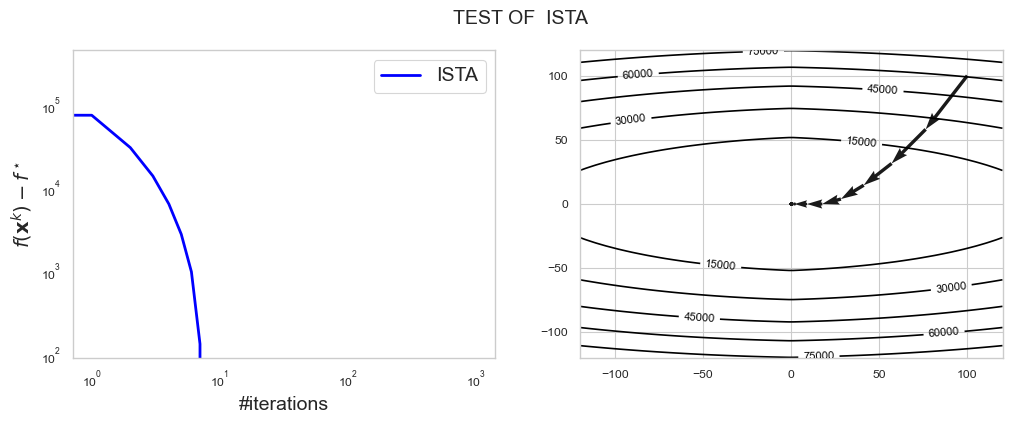

In [21]:
test_composite(ISTA, prox=l1_prox)


#### Question 5  (7 points)

Using the information in Lecture 7 slide 21 fill in the codes of the method $\text{FISTA}_\mu$.

In [22]:
@dataclass 
class FISTA_state(OptState):
    x_k: Vector
    y_k: Vector
    alpha_k: float
    c_f: float

In [23]:
def FISTA_update(composite_function, state):
    f, g = composite_function
    x_k, y_k, alpha_k, c_f = state

    next_x_k = g.prox(alpha_k, y_k - alpha_k * f.grad(y_k))
    next_y_k = next_x_k + (
        (np.sqrt(c_f) - 1.0) / (np.sqrt(c_f) + 1.0)
    ) * (next_x_k - x_k)

    return FISTA_state(
        x_k=next_x_k,
        y_k=next_y_k,
        alpha_k=alpha_k,
        c_f=c_f,
    )


def FISTA_initialize(composite_function, x_zero):
    f, g = composite_function
    L_f = f.lips_grad
    mu_f = f.strng_cvx
    c_f = L_f / mu_f
    alpha_k = 1.0 / L_f

    return FISTA_state(
        x_k=x_zero,
        y_k=x_zero,
        alpha_k=alpha_k,
        c_f=c_f,
    )

In [24]:
FISTA = OptAlgorithm(name="FISTA", init_state= FISTA_initialize, state_update=FISTA_update)

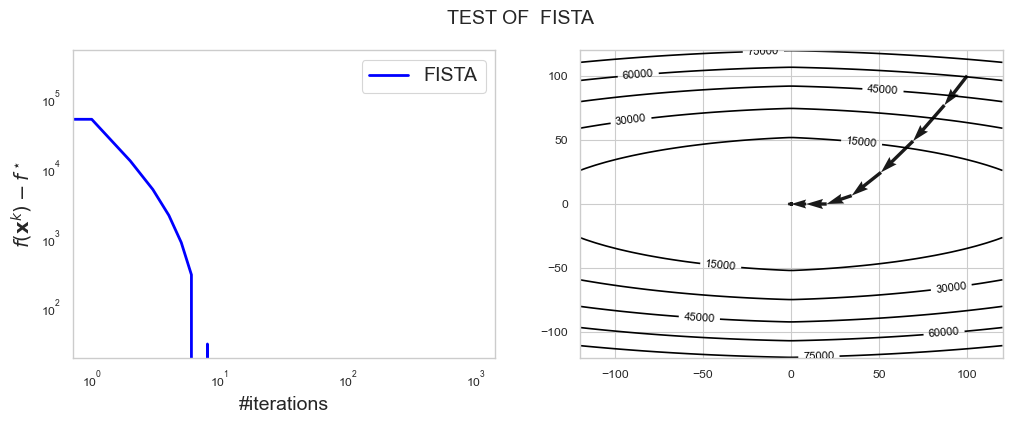

In [25]:
test_composite(FISTA, prox=l1_prox)


#### Question 6  (2 points)

Compare the convergence rates of the three methods and analyze whether the observed results align with their theoretical bounds.

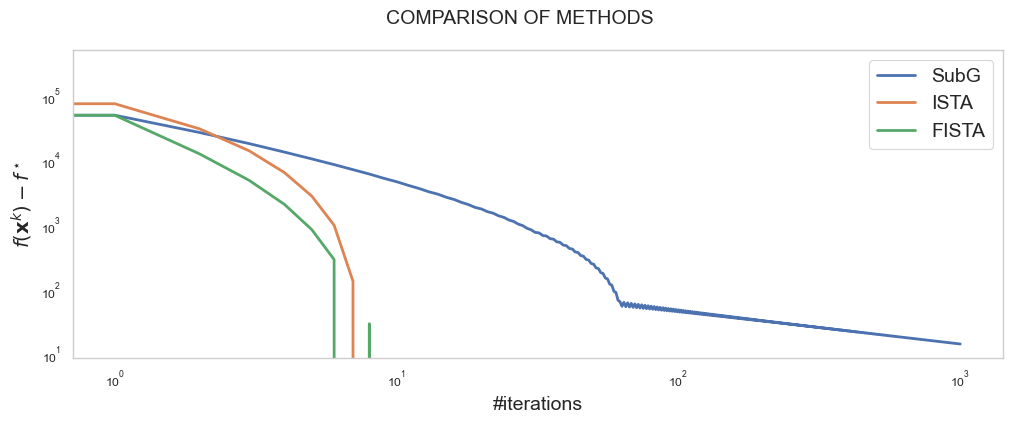

In [26]:
list_of_methods = [SubG, ISTA, FISTA]
compare_composite(list_of_methods, prox=l1_prox)


The results mostly agree with the theory.

SubG improves much more slowly. It uses $\alpha_k=0.1/\sqrt{k}$ without using the smoothness or strong convexity of $f$, and it has not reached zero after 1000 iterations. 
ISTA and FISTA use the proximal step and converge much faster. In this test $c_f=L/\mu=10$. ISTA uses $2/(L+\mu)$ and has iterate contraction factor $(c_f-1)/(c_f+1)=9/11\approx0.82$. FISTA uses momentum $m=(\sqrt{c_f}-1)/(\sqrt{c_f}+1)$ and has the accelerated bound $O((1-\sqrt{\mu/L})^k)$, with $1-\sqrt{\mu/L}\approx0.68$. ISTA reaches zero at about iteration 8, FISTA at about 7. The small bump in FISTA's curve is possible because accelerated methods may not decrease the objective at every step.

# Part 2: Application


We have now implemented multiple methods that can solve composite optimization problems. We will now apply them to an image inpainting problem.


Take a natural image, or better a picture of you, and place it in the same directory as this notebook.

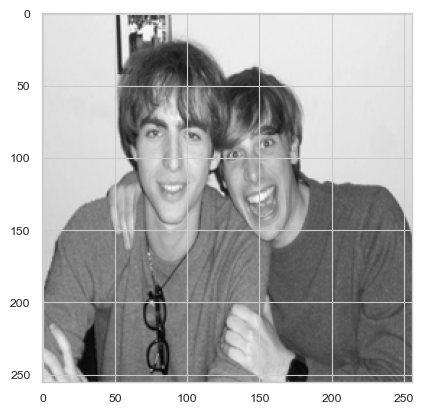

In [27]:
from lib.inpainting import *

image = load("lib/foto_io_e_umbi.jpg")  # FILL: replace with your image filename.

With this image in hand, let us subsample it and try to reconstruct the original.

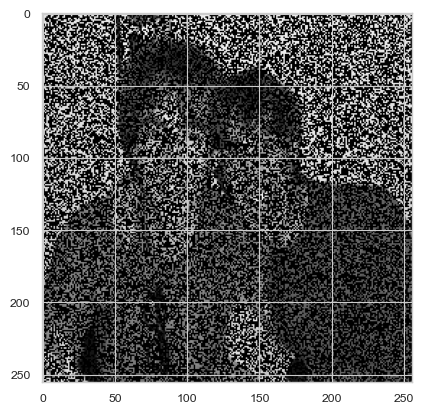

In [28]:
subsampled = show_subsampled(image)

For the rest of the questions, to ensure the function is 
$\mu$-strongly convex, we need to add an $\ell_2$ regularization term to it. As a result, we change the definition of $f_{\ell_1}(\mathbf{\alpha})$ as follows:
$$
    f_{\ell_1}(\mathbf{\alpha}) = \frac{1}{2}\|\mathbf{b} - \mathbf{P}_{\Omega} \mathbf{W}^T\mathbf{\alpha} \|_2^2 + \frac{1}{2}\mu \|\mathbf{\alpha}\|_2^2 
    $$

and the composite function becomes:
 $$
    \min_{\mathbf{\alpha} \in \mathbb{R}^{p}} \underbrace{ \frac{1}{2}\|\mathbf{b} - \mathbf{P}_{\Omega} \mathbf{W}^T\mathbf{\alpha} \|_2^2 + \frac{1}{2}\mu \|\mathbf{\alpha}\|_2^2 }_{f_{\ell_1}(\mathbf{\alpha})} + \underbrace{\lambda_{\ell_1} \|\mathbf{\alpha}\|_1}_{g_{\ell_1}(\mathbf{\alpha})},
    $$

By adding this regularization, we ensure better properties for optimization, making the solution more stable and well-behaved.

In the following cells we will define the optimization problems we need to solve to perform the reconstruction.

- We provide you with a function `P` that acts like the matrix $\mathbf{P}_{\Omega}$. That is, given a vector `x`, it returns a subsampled vector `P(x)` that corresponds to $\mathbf{P}_{\Omega} \mathbf{x}$. We also give you `P_T` which acts like $\mathbf{P}^\top$.
- We provide you with a function `W` and `W_T` that act like the matrix $\mathbf{W}$ and $\mathbf{W^\top}$ respectively. That is, for a vector `x`, `W(x)` and `W_T(x)` return $\mathbf{W}\mathbf{x}$ and $\mathbf{W^\top}\mathbf{x}$ respectively.

__(a)__ (1 point) Using these provided functions, define the observed variable `b` in the cell below.

In [29]:
from lib.inpainting import P, P_T, W, W_T

x = image.reshape(-1) #flattened image
print(image.shape)
print(x.shape)
print(W(x).shape)
print(P(x).shape)
b = P(x)  # subsampled image



(256, 256)
(65536,)
(65536,)
(26003,)


__(b)__ (1 point) Now define the function `f_l1` as described earlier in the problem text.

In [30]:
mu = 1e-4 # Desired strong convexity of f
def f_l1(alpha):
    residual = b - P(W_T(alpha))
    return 0.5 * np.dot(residual, residual) + 0.5 * mu * np.dot(alpha, alpha)

__(c)__ (1 point) Write the gradient of $f_{\ell_1}(\mathbf{\alpha})$.

residual = $\mathbf{b} - \mathbf{A}\boldsymbol\alpha$ and $\tfrac12\|residual(\alpha)\|^2$.



$$
\nabla_{\boldsymbol\alpha}\
= -\mathbf{A}^T\, residual
$$

and  $\nabla_{\boldsymbol\alpha}\ \tfrac{\mu}{2}\|\boldsymbol\alpha\|^2 = \mu\,\boldsymbol\alpha$.


In [31]:
def grad_f_l1(alpha):
    residual = P(W_T(alpha)) - b #changed sign
    return W(P_T(residual)) + mu * alpha

__(d)__ (1 points) Find the Lipschitz constant of $\nabla_\mathbf{\alpha} f_{\ell_1}(\mathbf{\alpha})$ analytically and fill it in the cell below. 

by def
$$
\big\|\nabla f_{\ell_1}(\boldsymbol\alpha) - \nabla f_{\ell_1}(\boldsymbol\beta)\big\| \le L\,\|\boldsymbol\alpha - \boldsymbol\beta\|.
$$

given that

$$
\nabla f_{\ell_1}(\boldsymbol\alpha) = \mathbf{W}\mathbf{P}_\Omega^T\big(\mathbf{P}_\Omega \mathbf{W}^T\boldsymbol\alpha - \mathbf{b}\big) + \mu\,\boldsymbol\alpha,
$$
$$
\nabla f_{\ell_1}(\boldsymbol\alpha) - \nabla f_{\ell_1}(\boldsymbol\beta)
= \mathbf{W}\mathbf{P}_\Omega^T\mathbf{P}_\Omega\mathbf{W}^T(\boldsymbol\alpha-\boldsymbol\beta) + \mu\,(\boldsymbol\alpha-\boldsymbol\beta)
= \underbrace{\big(\mathbf{W}\mathbf{P}_\Omega^T\mathbf{P}_\Omega\mathbf{W}^T + \mu\mathbb{I}\big)}_{=\,\nabla^2 f_{\ell_1}}(\boldsymbol\alpha-\boldsymbol\beta).
$$

Since , for a twice differentiable convex function, the smallest gradient Lipschitz constant is
$$
L=\sup_x\lambda_{\max}\!\left(\nabla^2 f(x)\right)
$$

Then, defining
$$
\mathbf A=\mathbf P_\Omega\mathbf W^T,
\qquad
\mathbf A^T=\mathbf W\mathbf P_\Omega^T.
$$
We use two properties of the operators:

1. $\mathbf W$ is orthogonal, so $\mathbf W^T\mathbf W=I$ by assumption (first cell in the notebook) 
2. $\mathbf P_\Omega$ selects distinct coordinates. Each row has exactly one entry equal to $1$, in a different position from the other rows. Thus each row has length $1$, and different rows have dot product $0$. Since the entries of $\mathbf P_\Omega\mathbf P_\Omega^T$ are these row dot products, $\mathbf P_\Omega\mathbf P_\Omega^T=I$. Note that $\mathbf P_\Omega$ has orthonormal rows but is generally not an orthogonal matrix. Our proof only uses the first identity.

Therefore, with $\mathbf A=\mathbf P_\Omega\mathbf W^T$,

$$
\mathbf A\mathbf A^T
=\mathbf P_\Omega
\underbrace{\mathbf W^T\mathbf W}_{I}
\mathbf P_\Omega^T
=\underbrace{\mathbf P_\Omega\mathbf P_\Omega^T}_{I}
=I.
$$

The singular values of $\mathbf A$ are the square roots of the eigenvalues of $\mathbf A\mathbf A^T$. Since every eigenvalue of $I$ is $1$,

$$
\sigma_{\max}(\mathbf A)=\sqrt{1}=1.
$$
$$
L = \lambda_{\max}\big(\nabla^2 f_{\ell_1}\big) = \lambda_{\max}\!\big(\mathbf{A}^T\mathbf{A}\big) + \mu = \sigma_{\max}\!\big(\mathbf{A}\big)^2 + \mu = 1 + \mu = 1.0001.
$$



In [32]:
lips_grad_f_l1 = 1.0 + mu

We have all the necessary ingredients to define the smooth part of our composite objective:

In [33]:
f_l1 = Function(f = f_l1, grad=grad_f_l1, lips_grad = lips_grad_f_l1, strng_cvx=mu)

For the non-smooth term, `l1` represents the unweighted $\ell_1$ norm. `Regularizer` applies the weight `lmda` to both the function value and its proximal operator, reusing `l1_prox` with $\beta=1$:

In [34]:
l1 = Function(f = lambda x: np.sum(np.abs(x), axis=0), prox=lambda gamma, z: l1_prox(gamma, z, beta=1))

g_l1 = Regularizer(l1)

In [35]:
composite_objective = CompositeFunction(f=f_l1, g=g_l1)

With the objective defined, we provide you with a function with the following signature:
```python
solve_composite(method: OptAlgorithm, composite_objective: CompositeFunction, lmda: float, max_iterations: int) -> Vector
```

In other words, the function takes an optimization algorithm `method`, a CompositeFunction `composite_objective`, a regularization parameter `lmda` and a number of iterations `max_iterations` and returns a vector which is the last iterate given by the `method`.



In [36]:
from lib.inpainting import solve_composite

__(e)__ (5 points) Using `solve_composite` reconstruct the subsampled image. Recall that the composite problem solves for $\mathbf{\alpha}$ so you need to convert the output back to an image and visualize it.

Select a reasonable value for `lmda`.

**Bonus (2 points).** Using `solve_composite` and the `PSNR` metric, find the best value for `lmda`.

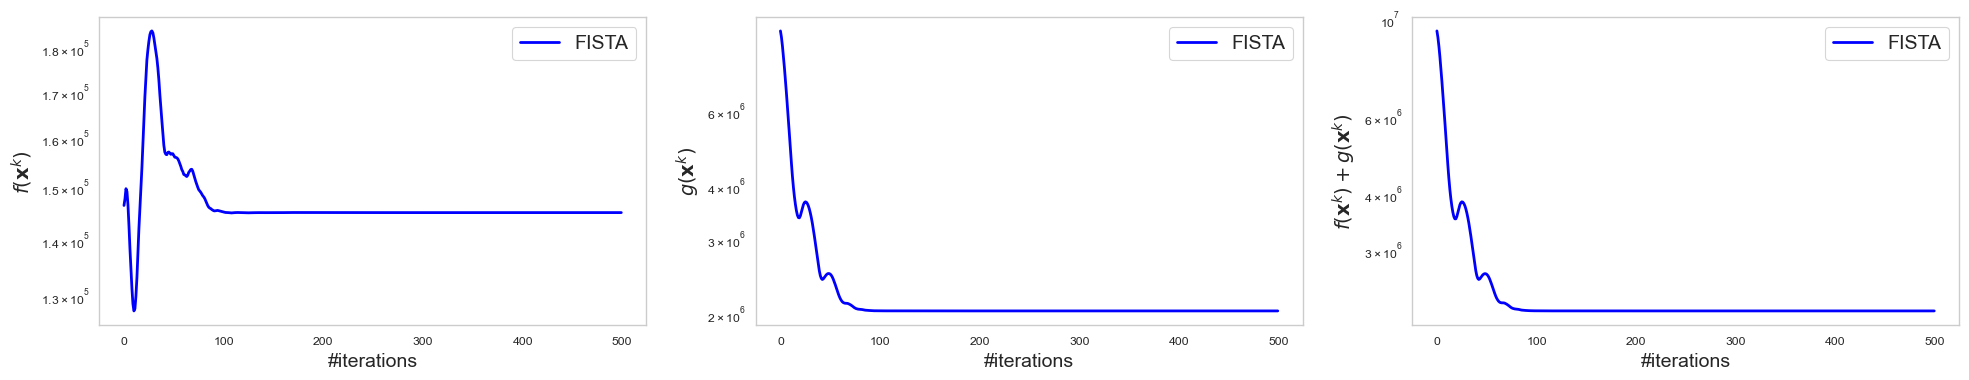

In [37]:
lmda = 2.5
out = solve_composite(FISTA, composite_objective, lmda=lmda, max_iterations=500)  # solves for alpha
flat_image_out = W_T(out)      # x = W^T alpha : back to pixel space
image_out = flat_image_out.reshape(256, 256)

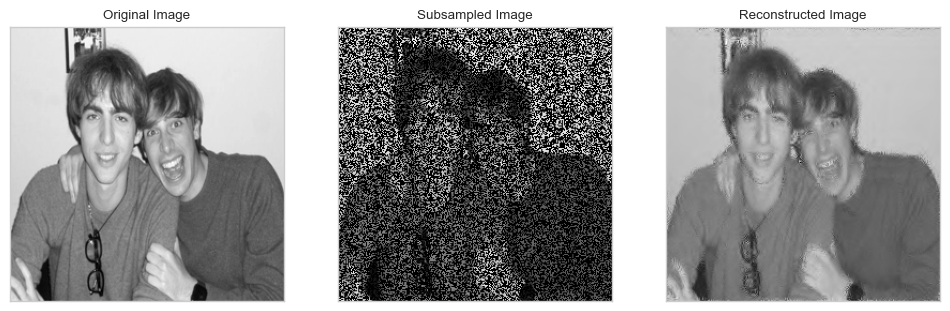

In [38]:
show(true = image, subsampled=subsampled, estimated=image_out)

lmda =  0.50: PSNR = 26.86 dB
lmda =  0.70: PSNR = 26.92 dB
lmda =  0.97: PSNR = 26.98 dB
lmda =  1.36: PSNR = 27.02 dB
lmda =  1.89: PSNR = 27.04 dB
lmda =  2.64: PSNR = 27.04 dB
lmda =  3.68: PSNR = 27.01 dB
lmda =  5.14: PSNR = 26.95 dB
lmda =  7.17: PSNR = 26.80 dB
lmda = 10.00: PSNR = 26.53 dB

Best lmda = 1.89 (PSNR = 27.04 dB)


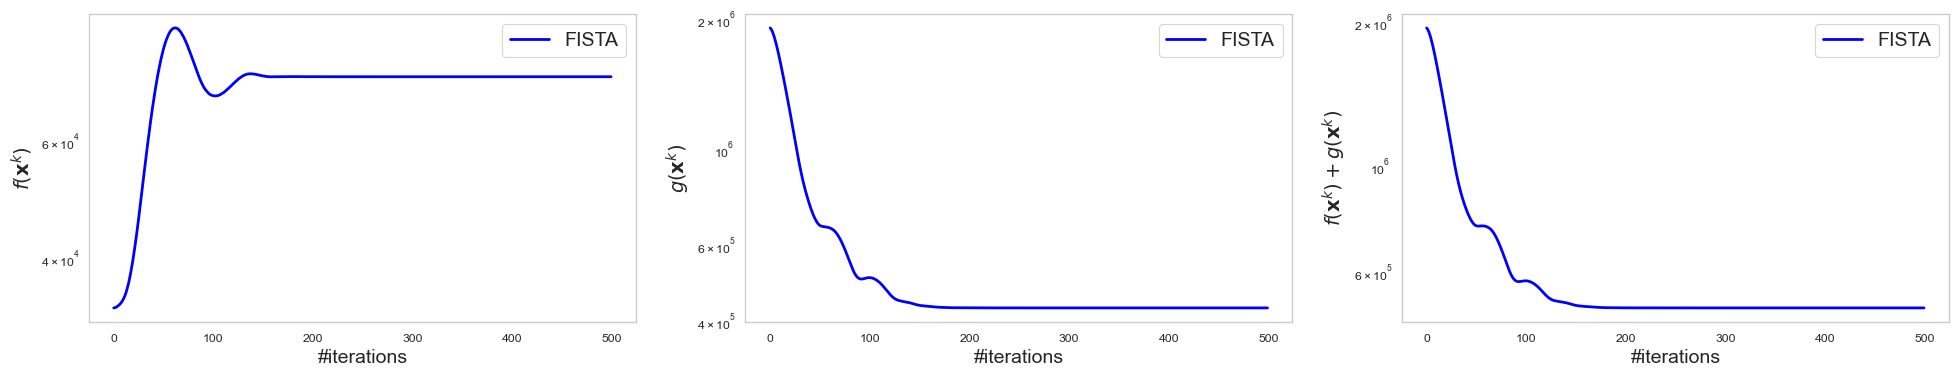

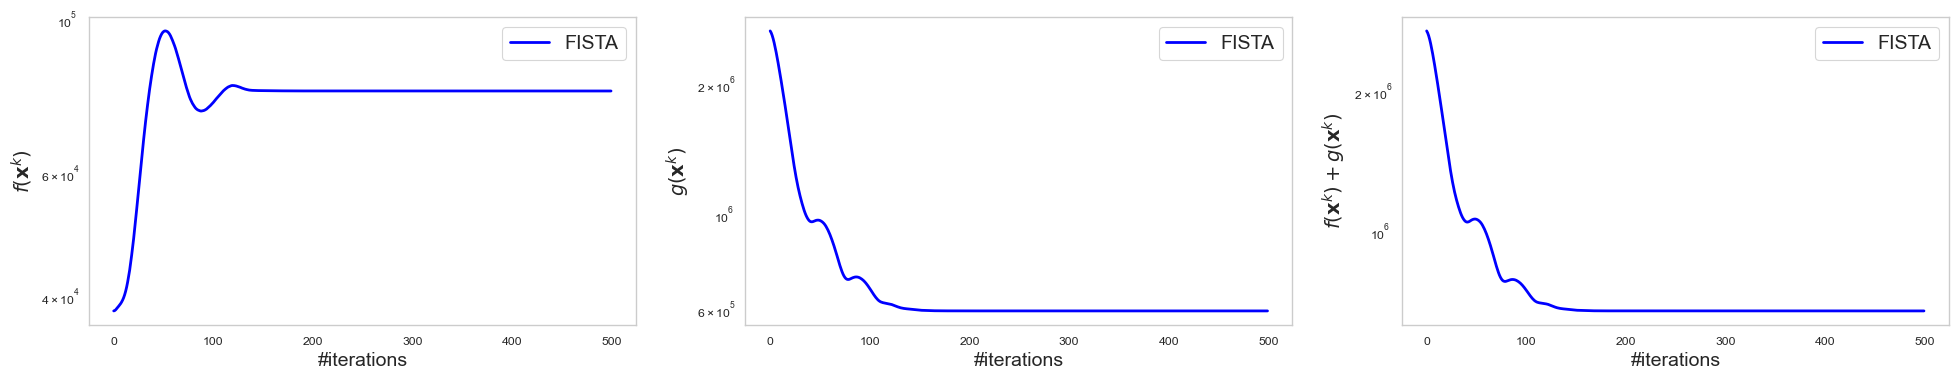

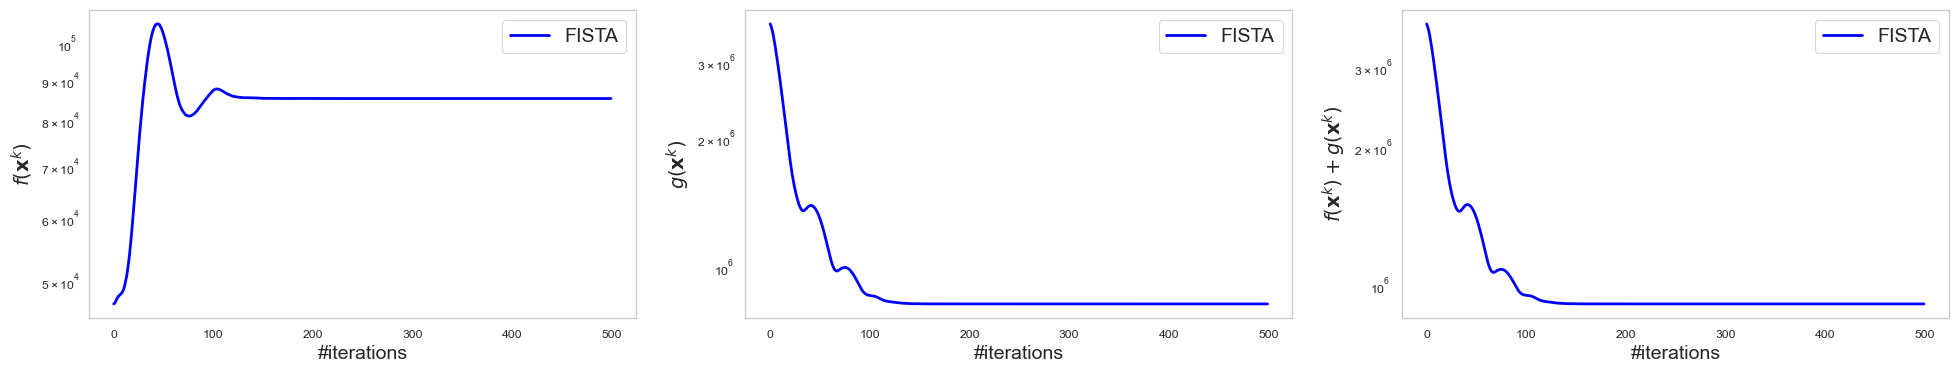

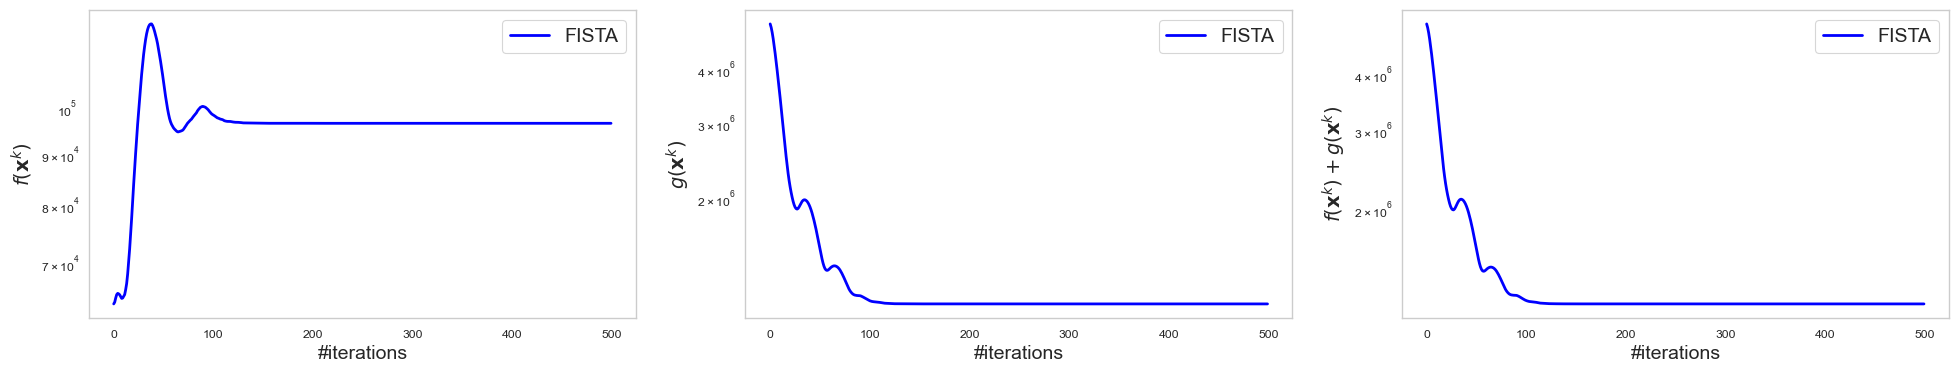

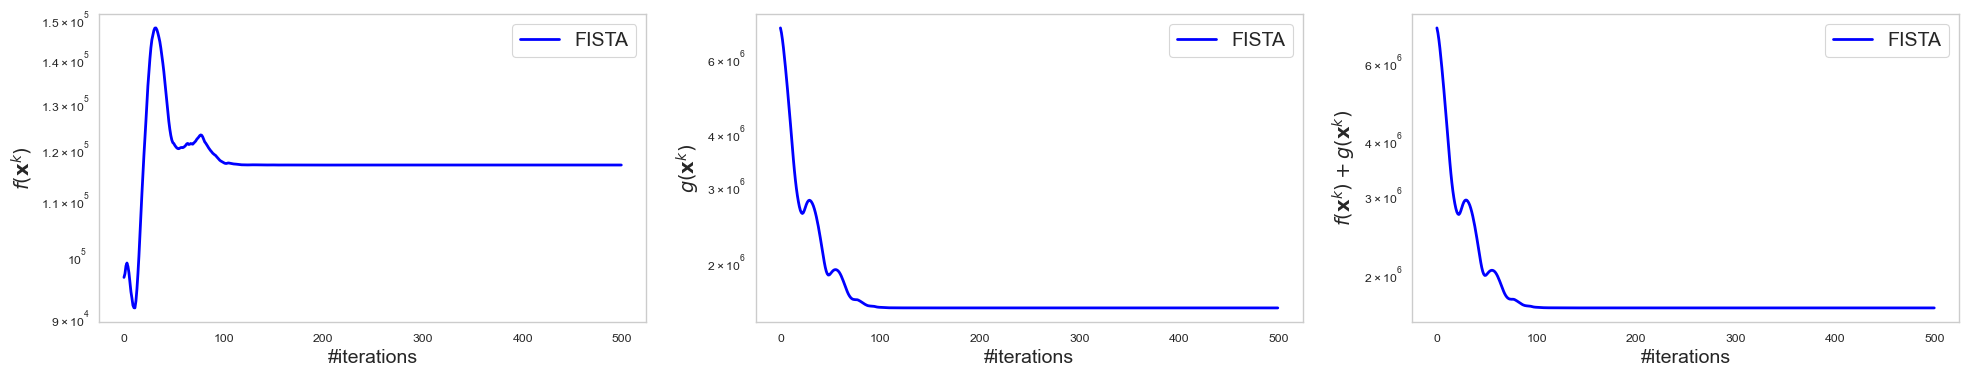

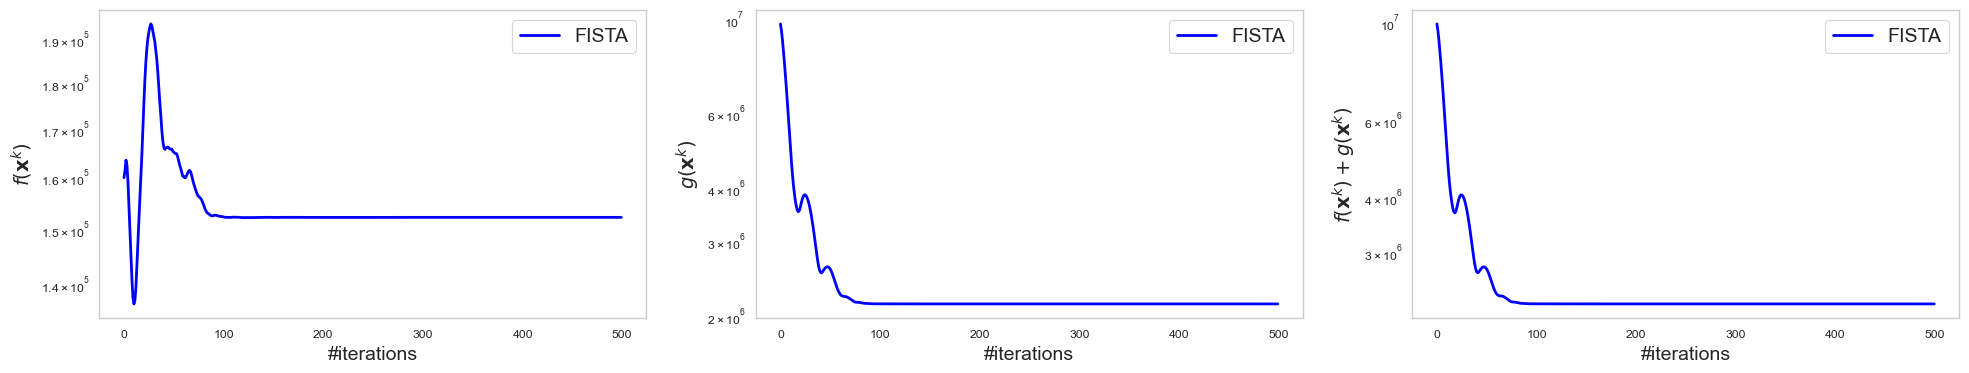

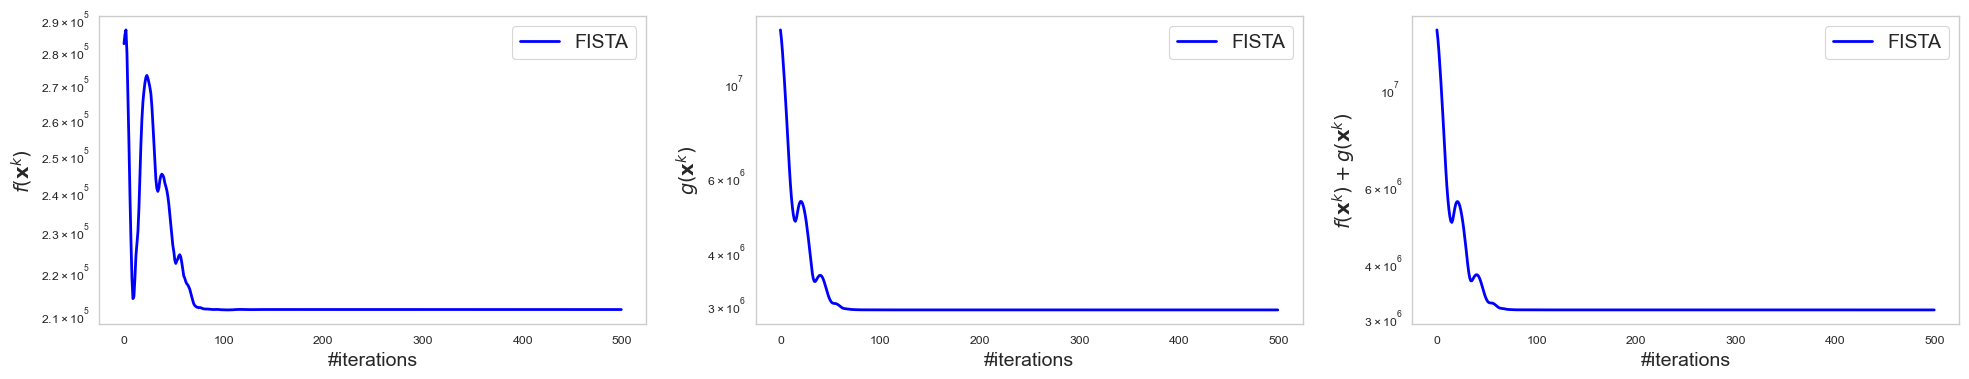

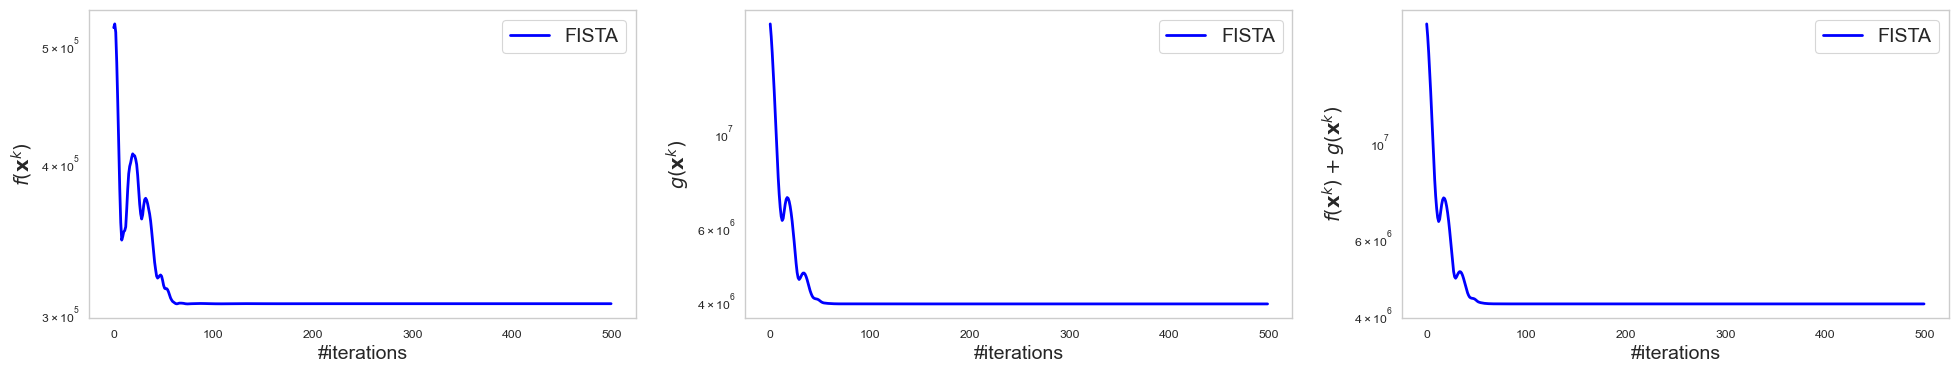

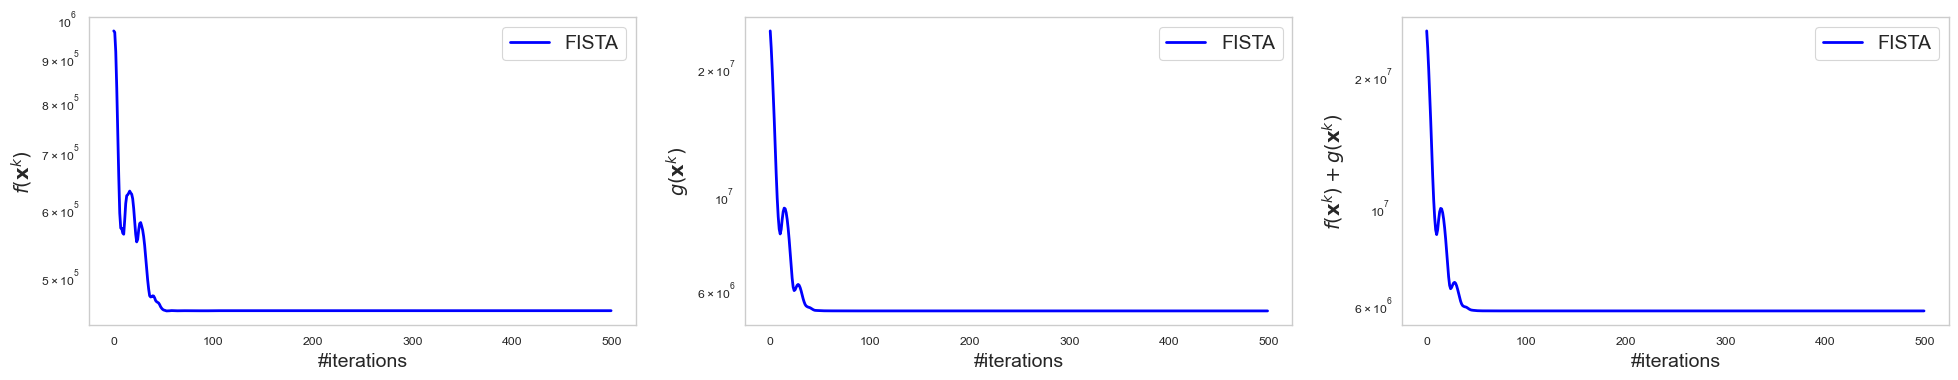

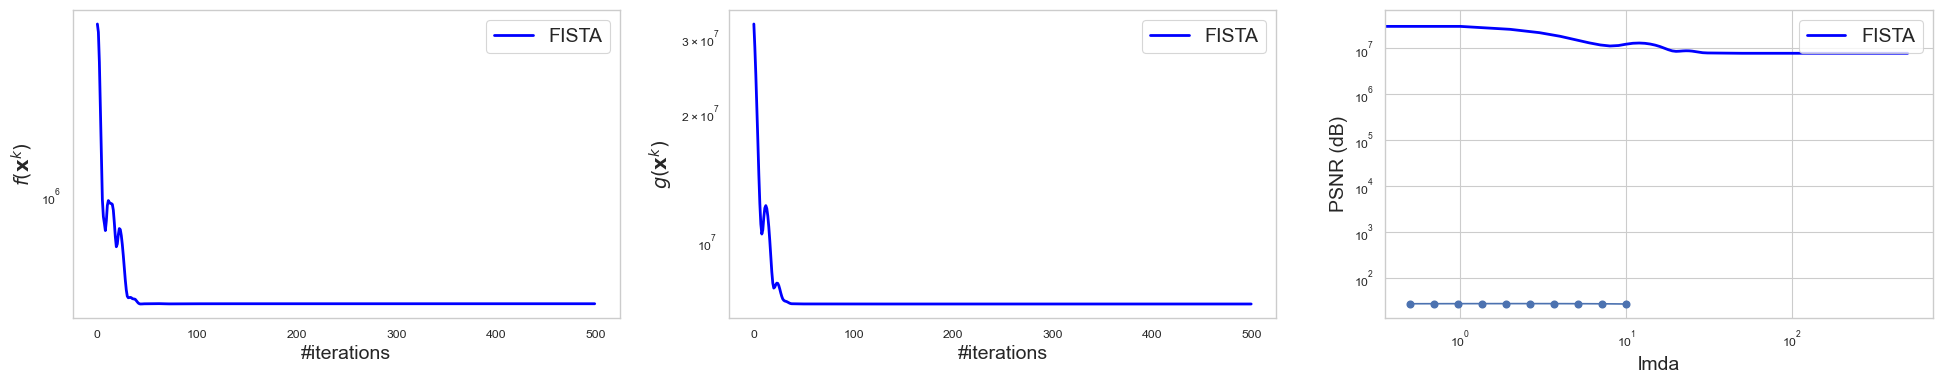

In [39]:
def psnr(estimated, true):
    """Peak signal-to-noise ratio between two images (higher is better)."""
    mse = np.mean((estimated - true) ** 2)
    return 10.0 * np.log10(255.0**2 / mse)


lmda_grid = np.geomspace(0.5, 10.0, 10)
max_iterations = 500

psnr_values = []
for lmda in lmda_grid:
    alpha_hat = solve_composite(FISTA, composite_objective, lmda, max_iterations)
    estimated = W_T(alpha_hat).reshape(image.shape)
    score = psnr(estimated, image)
    psnr_values.append(score)
    print(f"lmda = {lmda:5.2f}: PSNR = {score:.2f} dB")

best_lmda = lmda_grid[np.argmax(psnr_values)]
print(f"\nBest lmda = {best_lmda:.2f} (PSNR = {max(psnr_values):.2f} dB)")

plt.semilogx(lmda_grid, psnr_values, "o-")
plt.xlabel("lmda")
plt.ylabel("PSNR (dB)")
plt.grid()
plt.show()